# Distance × internal representation — exploratory reanalysis
2026-11-24 | Qwen2.5-0.5B-Instruct

既存4概念・64 Cueの保存済み結果を再解析する。主対象は Avoid X の連続距離との関係、Neutral X は対応する比較条件。GPU・OpenAI API不要。新規生成なし。関連48 Cueのみを回帰対象とし、無関係16 CueとCueなし4件は別集計。ProbeはX/Y相対判別値、Lensは候補文字列の系列対数尤度差であり、思考量ではない。探索的な記述分析であり、因果効果や一般化を主張しない。


In [1]:
import io, json, hashlib, os, re, subprocess, tempfile
from pathlib import Path
from datetime import datetime, timezone
import requests, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, spearmanr
from IPython.display import display, Markdown

REPO = "ryouy/GraduationThesis"
BRANCH = "main"
RUN_ID = "20261124_distance_reanalysis_v1"
DEST = "experiments/2026-11/1124_distance_representation_analysis/results/" + RUN_ID
ROOT = "experiments/2026-11/1112_qwen_suppression_pilot/results/"
OLD = ROOT + "20261112_qwen_suppression_pilot_v1/"
NEW = ROOT + "20261124_qwen_neutral_x_addon_v1/"
OUT = Path("/content/distance_analysis") / RUN_ID
OUT.mkdir(parents=True, exist_ok=True)
# Public repository: no token needed for reading. Token is optional for publishing.
try:
    from google.colab import userdata
    try: TOKEN = userdata.get("GITHUB_RESULTS_TOKEN")
    except Exception: TOKEN = None
except ImportError:
    TOKEN = os.environ.get("GITHUB_RESULTS_TOKEN")
session = requests.Session()
headers = {"Authorization": "Bearer " + TOKEN} if TOKEN else {}
api = "https://api.github.com/repos/" + REPO
resp = session.get(api + "/commits/" + BRANCH, headers=headers, timeout=60)
resp.raise_for_status()
SOURCE_SHA = resp.json()["sha"]
source_hashes = {}
def read_bytes(path):
    url = f"https://raw.githubusercontent.com/{REPO}/{SOURCE_SHA}/{path}"
    response = session.get(url, timeout=90)
    response.raise_for_status()
    data = response.content
    source_hashes[path] = hashlib.sha256(data).hexdigest()
    return data
def csv(path):
    return pd.read_csv(io.BytesIO(read_bytes(path)))
print("Source commit:", SOURCE_SHA)




Source commit: 97a9c30fb836a1bf6b16af6e31e0611293ea8f0e


## 1. 入力の照合と品質管理
同じCue・条件・層を対応付け、重複・欠損・非有限値を検出する。元データのSHA-256と参照コミットを保存する。


In [2]:
cue = csv(OLD + "cue_selected.csv")
cue2 = csv(NEW + "cue_selected.csv")
assert source_hashes[OLD+"cue_selected.csv"] == source_hashes[NEW+"cue_selected.csv"], "Cue mismatch"
m1 = json.loads(read_bytes(OLD+"manifest.json"))
m2 = json.loads(read_bytes(NEW+"manifest.json"))
# The manifests hash the original frozen stimulus file, not the re-exported CSV.
FROZEN = "experiments/2026-11/1112_cue_semantic_distance/final_stimuli/20261112_frozen_ai_audit_v1/cue_final_FROZEN_AI_AUDITED.csv"
original = csv(FROZEN)
assert m1["cue_sha256"] == m2["cue_sha256"] == source_hashes[FROZEN], "Frozen source hash mismatch"
# Re-exporting through pandas can alter numeric serialization without changing stimuli.
pd.testing.assert_frame_equal(original, cue, check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12)
pd.testing.assert_frame_equal(original, cue2, check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12)
print("Frozen cue hash and both exported stimulus tables verified.")
keys = ["target_x","cue_id"]
assert len(cue)==64 and not cue.duplicated(keys).any()
assert cue.groupby(["target_x","distance_band"]).size().eq(4).all()
assert set(cue.distance_band)=={"near","medium","far","unrelated"}
assert np.isfinite(cue.distance_x).all()
CONCEPTS = sorted(cue.target_x.unique())
CONDS = ["Avoid X","Neutral X"]
BANDS = ["near","medium","far","unrelated"]
COLORS = {"Avoid X":"#2468a2","Neutral X":"#c17a35"}
def paired(filename, metric, layers):
    raw = csv(NEW+filename)
    assert not raw.duplicated(keys+["layer"]).any()
    assert set(raw.layer)==set(layers)
    assert len(raw)==68*len(layers)
    assert np.isfinite(raw[CONDS].to_numpy()).all()
    long = raw.melt(id_vars=keys+["distance_band","layer"],value_vars=CONDS,
                    var_name="condition",value_name="score")
    merged = long.merge(cue[keys+["distance_x","distance_y","word_count","comparator_y","distance_band"]],
                        on=keys,how="left",validate="many_to_one",suffixes=("","_cue"),indicator=True)
    noncontrol=merged.cue_id.ne("NO_CUE")
    assert merged.loc[noncontrol,"_merge"].eq("both").all()
    assert merged.loc[noncontrol,"distance_band"].eq(merged.loc[noncontrol,"distance_band_cue"]).all()
    assert merged.loc[~noncontrol,"distance_band"].eq("none").all()
    merged["metric"]=metric
    return merged.drop(columns=["_merge","distance_band_cue"])
probe=paired("paired_cue_probe_effects.csv","Probe",range(22,25))
lens=paired("paired_cue_lens_effects.csv","Logit Lens",range(1,25))
# Cross-check paired Probe values against the original condition-specific scores.
for condition,base in [("Avoid X",OLD),("Neutral X",NEW)]:
    p=csv(base+"probe_scores.csv")
    p=p[p.input_id.str.endswith("__"+condition.replace(" ","_"))]
    expected=probe[probe.condition.eq(condition)].copy()
    expected["input_id"]=expected.target_x+"__"+expected.cue_id+"__"+condition.replace(" ","_")
    check=expected.merge(p,on=["input_id","layer"],validate="one_to_one")
    assert len(check)==len(expected)
    assert np.allclose(check.score,check.x_vs_y_decision,rtol=1e-8,atol=1e-8)
data=pd.concat([probe,lens],ignore_index=True)
related=data[data.distance_band.isin(BANDS[:3])].copy()
assert related.groupby(["metric","target_x","condition","layer"]).size().eq(12).all()
data.to_csv(OUT/"all_scores_with_distance.csv",index=False)
display(related.groupby(["metric","condition"]).size().rename("rows"))
display(cue.groupby(["target_x","distance_band"]).distance_x.agg(["min","mean","max"]))





Frozen cue hash and both exported stimulus tables verified.


metric      condition
Logit Lens  Avoid X      1152
            Neutral X    1152
Probe       Avoid X       144
            Neutral X     144
Name: rows, dtype: int64

min      mean       max
target_x   distance_band                              
bicycle    far            0.924307  0.936379  0.948416
           medium         0.766412  0.822145  0.868777
           near           0.457433  0.590809  0.720726
           unrelated      0.933791  1.009289  1.099355
boat       far            0.810676  0.876520  0.917964
           medium         0.737615  0.762421  0.791860
           near           0.515056  0.591836  0.659215
           unrelated      0.872590  0.966553  1.059427
bus        far            0.792845  0.855419  0.925044
           medium         0.698331  0.718362  0.742773
           near           0.474011  0.564486  0.634564
           unrelated      0.897180  0.994382  1.101918
motorcycle far            0.872862  0.914172  0.940198
           medium         0.791953  0.797974  0.804660
           near           0.544705  0.608397  0.688302
           unrelated      0.960828  1.013810  1.060155

## 2. 概念別の連続距離分析
OLS傾き・Pearson r・Spearman ρを記述的に算出。各概念・各条件・各層で関連12 Cue。異なるProbeの生スコアを平均しない。


In [3]:
def stats(g):
    x=g.distance_x.to_numpy(); y=g.score.to_numpy()
    if np.ptp(x)==0 or np.ptp(y)==0:
        return pd.Series(dict(n=len(g),slope=np.nan,pearson_r=np.nan,spearman_rho=np.nan))
    fit=linregress(x,y)
    return pd.Series(dict(n=len(g),slope=fit.slope,intercept=fit.intercept,
                          pearson_r=fit.rvalue,spearman_rho=spearmanr(x,y).statistic))
groupcols=["metric","target_x","condition","layer"]
summary=related.groupby(groupcols,sort=True).apply(lambda g: stats(g[['distance_x','score']])).reset_index()
summary.to_csv(OUT/"distance_statistics.csv",index=False)
display(summary.query("layer == 24").round(3))
# Paired slope difference: regress the within-cue Avoid-minus-Neutral score on distance.
wide=related.pivot(index=["metric","target_x","cue_id","layer","distance_x"],columns="condition",values="score").reset_index()
wide["score"]=wide["Avoid X"]-wide["Neutral X"]
diff=wide.groupby(["metric","target_x","layer"]).apply(lambda g: stats(g[['distance_x','score']])).reset_index()
diff.to_csv(OUT/"paired_slope_difference.csv",index=False)
display(diff.query("layer == 24").round(3))




/tmp/ipykernel_629/3242486385.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary=related.groupby(groupcols,sort=True).apply(lambda g: stats(g[['distance_x','score']])).reset_index()


,metric,target_x,condition,layer,n,slope,intercept,pearson_r,spearman_rho
23,Logit Lens,bicycle,Avoid X,24,12.0,-4.116,13.964,-0.254,-0.420
47,Logit Lens,bicycle,Neutral X,24,12.0,-2.208,13.921,-0.168,-0.182
71,Logit Lens,boat,Avoid X,24,12.0,-8.371,13.120,-0.581,-0.559
95,Logit Lens,boat,Neutral X,24,12.0,-6.621,12.424,-0.517,-0.434
119,Logit Lens,bus,Avoid X,24,12.0,-5.815,12.660,-0.433,-0.266
143,Logit Lens,bus,Neutral X,24,12.0,-5.072,13.005,-0.483,-0.385
167,Logit Lens,motorcycle,Avoid X,24,12.0,8.306,0.976,0.569,0.399
191,Logit Lens,motorcycle,Neutral X,24,12.0,6.404,3.104,0.574,0.357
194,Probe,bicycle,Avoid X,24,12.0,-1.433,0.705,-0.251,-0.126
197,Probe,bicycle,Neutral X,24,12.0,-1.520,0.961,-0.303,-0.252


/tmp/ipykernel_629/3242486385.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  diff=wide.groupby(["metric","target_x","layer"]).apply(lambda g: stats(g[['distance_x','score']])).reset_index()


,metric,target_x,layer,n,slope,intercept,pearson_r,spearman_rho
23,Logit Lens,bicycle,24,12.0,-1.908,0.044,-0.497,-0.671
47,Logit Lens,boat,24,12.0,-1.751,0.695,-0.586,-0.643
71,Logit Lens,bus,24,12.0,-0.742,-0.344,-0.124,-0.105
95,Logit Lens,motorcycle,24,12.0,1.902,-2.128,0.329,0.217
98,Probe,bicycle,24,12.0,0.087,-0.256,0.081,0.105
101,Probe,boat,24,12.0,-0.424,0.526,-0.337,-0.336
104,Probe,bus,24,12.0,0.158,-0.585,0.089,0.168
107,Probe,motorcycle,24,12.0,0.150,-0.712,0.066,0.035


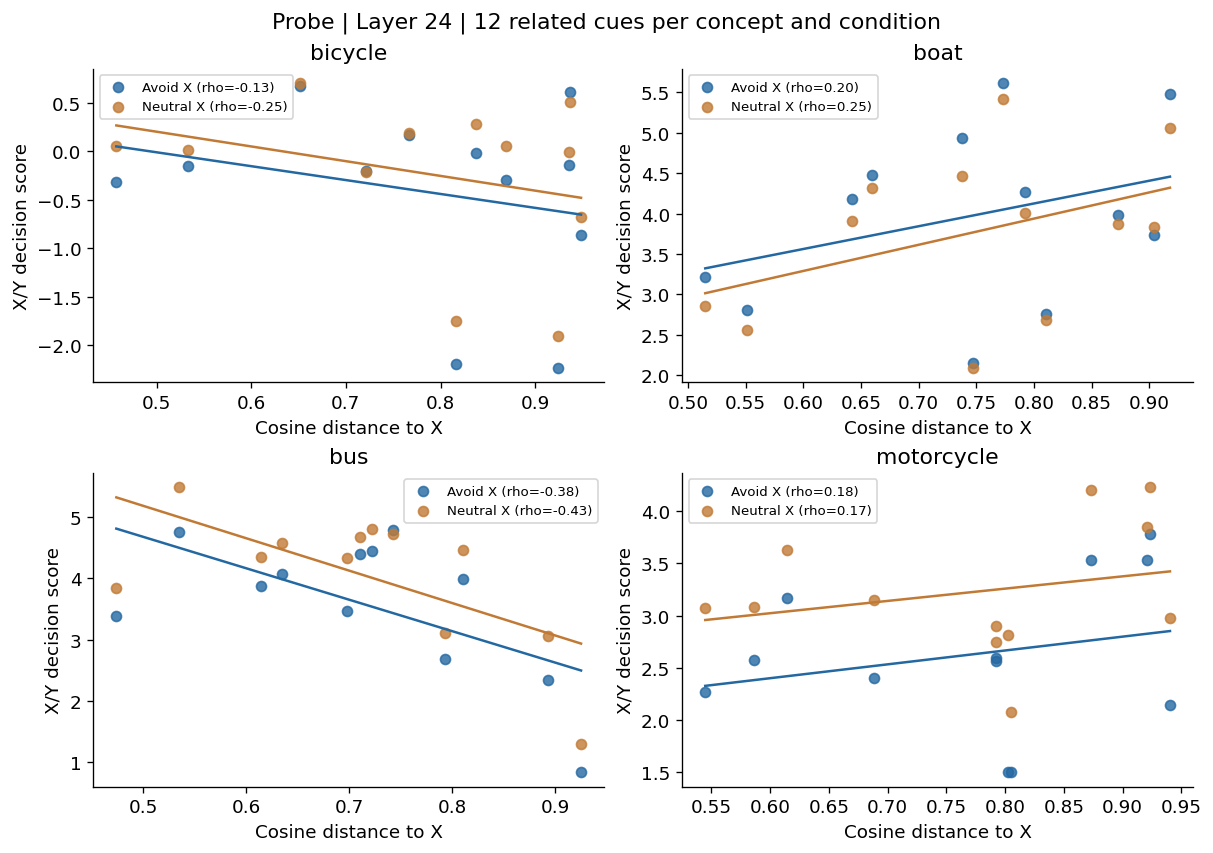

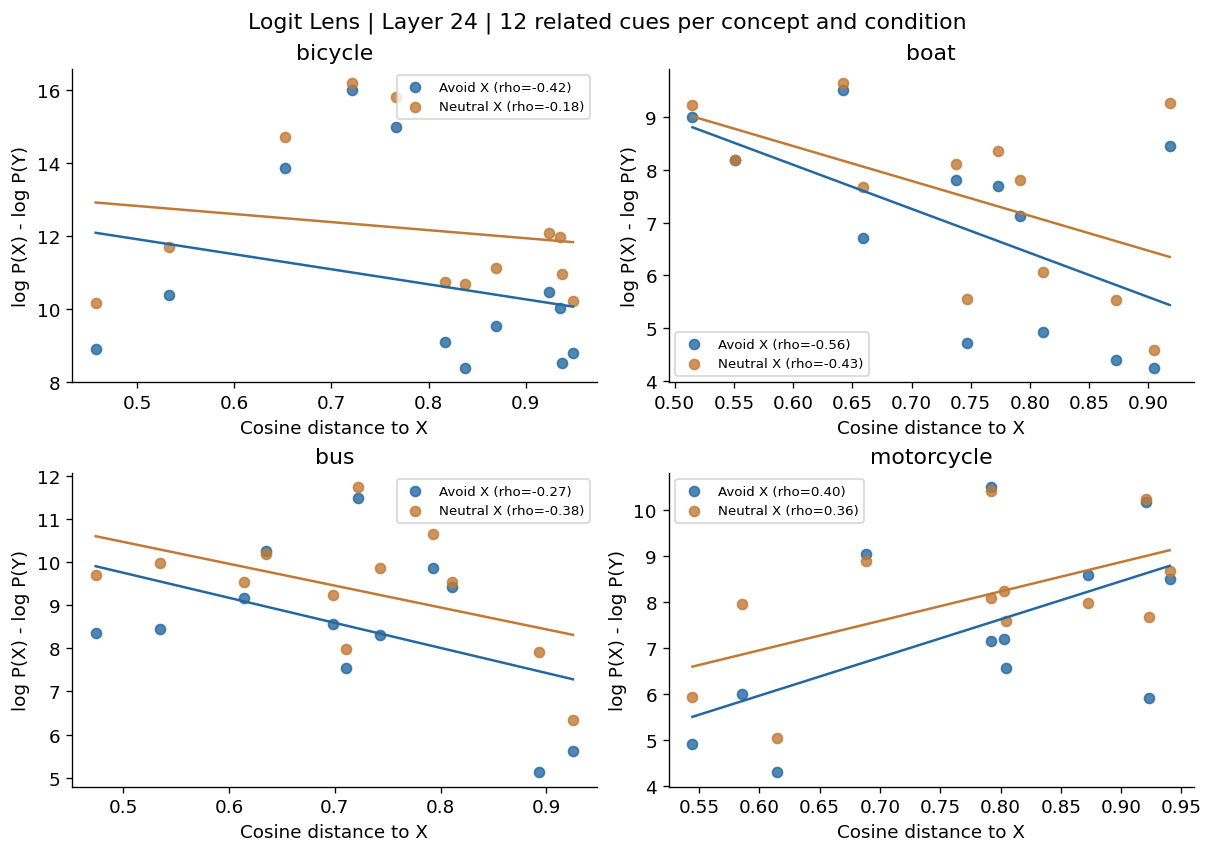

In [4]:
plt.rcParams.update({"figure.dpi":120,"font.size":11,"axes.spines.top":False,"axes.spines.right":False})
def save(fig,name):
    fig.savefig(OUT/(name+".png"),dpi=220,bbox_inches="tight")
    fig.savefig(OUT/(name+".pdf"),bbox_inches="tight")
    plt.show(); plt.close(fig)
for metric in ["Probe","Logit Lens"]:
    fig,axes=plt.subplots(2,2,figsize=(10,7),layout="constrained")
    for ax,target in zip(axes.flat,CONCEPTS):
        for cond in CONDS:
            g=related.query("metric == @metric and target_x == @target and condition == @cond and layer == 24")
            s=summary.query("metric == @metric and target_x == @target and condition == @cond and layer == 24").iloc[0]
            ax.scatter(g.distance_x,g.score,color=COLORS[cond],alpha=.8,label=f"{cond} (rho={s.spearman_rho:.2f})")
            xx=np.array([g.distance_x.min(),g.distance_x.max()])
            ax.plot(xx,s.intercept+s.slope*xx,color=COLORS[cond])
        ax.set(title=target,xlabel="Cosine distance to X",ylabel="X/Y decision score" if metric=="Probe" else "log P(X) - log P(Y)")
        ax.legend(fontsize=8)
    fig.suptitle(f"{metric} | Layer 24 | 12 related cues per concept and condition")
    save(fig,metric.lower().replace(" ","_")+"_distance_scatter")




## 3. Logit Lensの層別推移
距離帯ごとに4 Cueの平均を概念別に表示。無関係・Cueなしは距離回帰に含めず、次節で別集計する。層の進行は生成時間ではない。


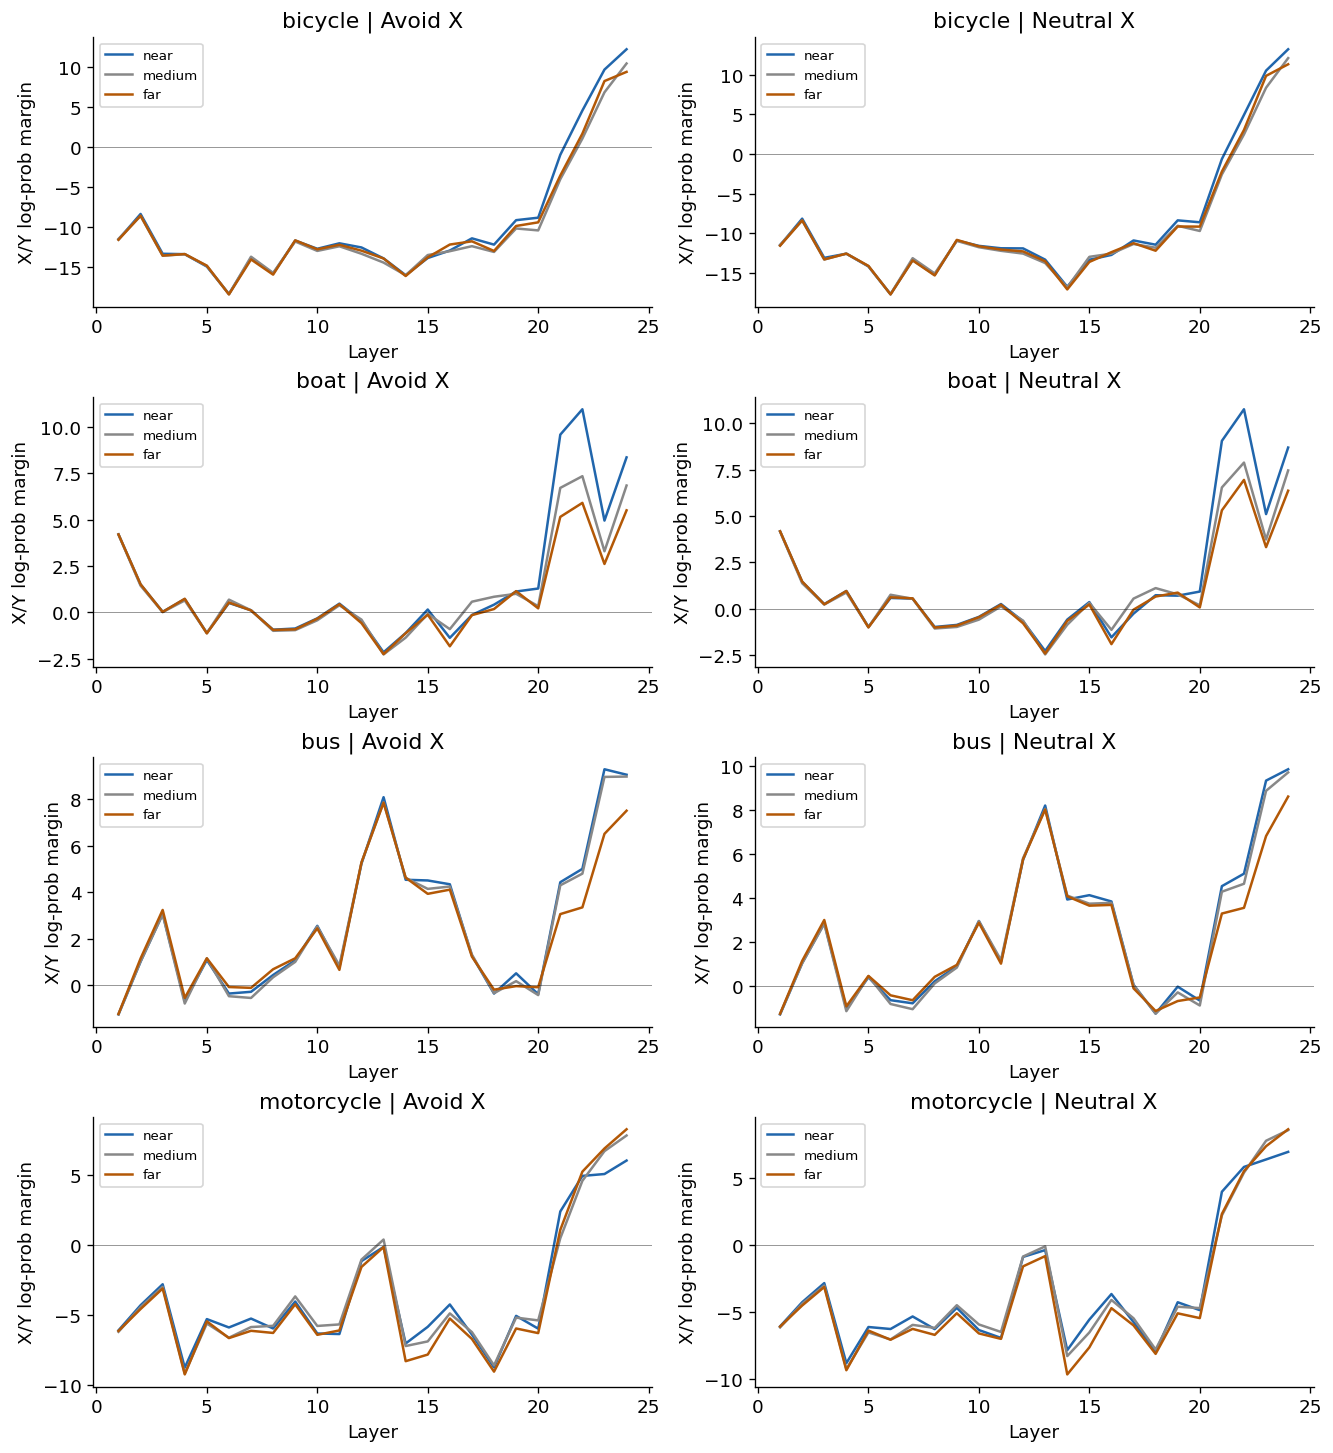

In [5]:
band_colors={"near":"#2166ac","medium":"#888888","far":"#b35806"}
fig,axes=plt.subplots(4,2,figsize=(11,12),layout="constrained")
for i,target in enumerate(CONCEPTS):
    for j,cond in enumerate(CONDS):
        ax=axes[i,j]
        g=related.query("metric == 'Logit Lens' and target_x == @target and condition == @cond")
        for band in BANDS[:3]:
            a=g[g.distance_band.eq(band)].groupby("layer").score.agg(["mean","std"])
            ax.plot(a.index,a["mean"],label=band,color=band_colors[band])
        ax.set(title=f"{target} | {cond}",xlabel="Layer",ylabel="X/Y log-prob margin")
        ax.axhline(0,color="black",lw=.6,alpha=.4)
        ax.legend(fontsize=8)
save(fig,"logit_lens_by_distance_band")




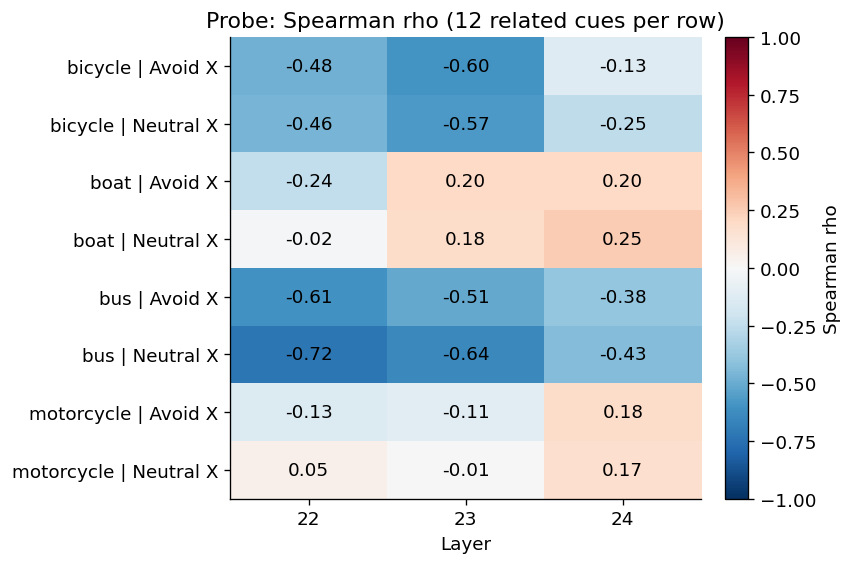

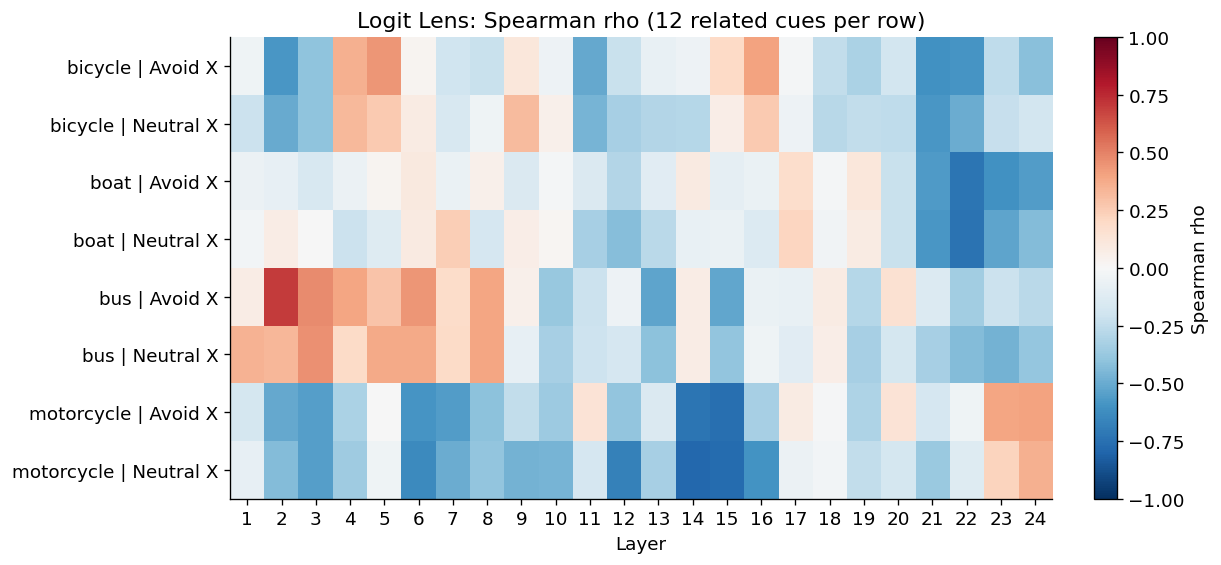

In [6]:
# Layer-wise Spearman correlations, one row per concept and condition.
for metric in ["Probe","Logit Lens"]:
    g=summary[summary.metric.eq(metric)].copy()
    g["row"]=g.target_x+" | "+g.condition
    a=g.pivot(index="row",columns="layer",values="spearman_rho")
    fig,ax=plt.subplots(figsize=(max(7,len(a.columns)*.42),4.6),layout="constrained")
    im=ax.imshow(a.to_numpy(),aspect="auto",cmap="RdBu_r",vmin=-1,vmax=1)
    ax.set_xticks(range(len(a.columns)),a.columns)
    ax.set_yticks(range(len(a.index)),a.index)
    ax.set(xlabel="Layer",title=f"{metric}: Spearman rho (12 related cues per row)")
    if len(a.columns)<=3:
        for i in range(len(a.index)):
            for j in range(len(a.columns)):
                ax.text(j,i,f"{a.iloc[i,j]:.2f}",ha="center",va="center")
    fig.colorbar(im,ax=ax,label="Spearman rho")
    save(fig,metric.lower().replace(" ","_")+"_correlation_heatmap")




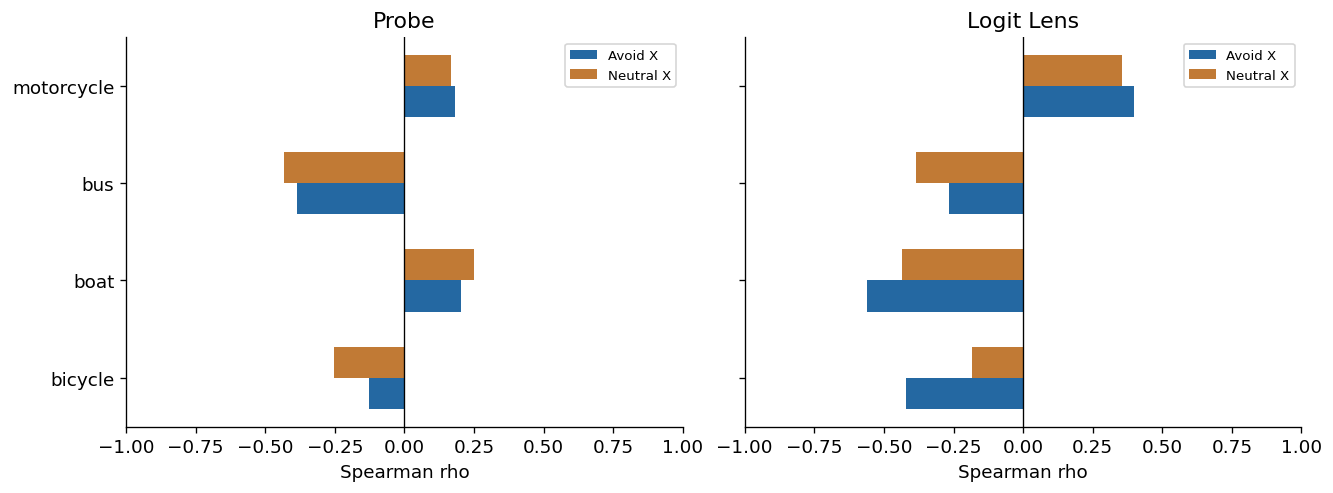

In [7]:
# Final-layer correlations: comparable dimensionless summaries, not pooled raw scores.
fig,axes=plt.subplots(1,2,figsize=(11,4),layout="constrained",sharey=True)
for ax,metric in zip(axes,["Probe","Logit Lens"]):
    g=summary.query("metric == @metric and layer == 24")
    for j,cond in enumerate(CONDS):
        s=g[g.condition.eq(cond)].set_index("target_x").reindex(CONCEPTS)
        ax.barh(np.arange(len(CONCEPTS))+(j-.5)*.32,s.spearman_rho,height=.32,color=COLORS[cond],label=cond)
    ax.set_yticks(range(len(CONCEPTS)),CONCEPTS)
    ax.set(xlim=(-1,1),xlabel="Spearman rho",title=metric)
    ax.axvline(0,color="black",lw=.8); ax.legend(fontsize=8)
save(fig,"final_layer_concept_correlations")




## 4. 対照と感度分析
無関係・Cueなしは別集計。Y距離・文長との相関も確認するが、12 Cueで複雑なモデルを適合しない。


In [8]:
controls=data[~data.distance_band.isin(BANDS[:3])].groupby(
    ["metric","target_x","condition","layer","distance_band"]).score.agg(["size","mean","std"]).reset_index()
controls.to_csv(OUT/"controls_separate.csv",index=False)
display(controls.query("layer == 24").round(3))
sensitivity=[]
for key,g in related.query("layer == 24").groupby(groupcols):
    for variable in ["distance_y","word_count"]:
        rho=spearmanr(g[variable],g.score).statistic if g[variable].nunique()>1 else np.nan
        sensitivity.append(dict(zip(groupcols,key),variable=variable,spearman_rho=rho))
pd.DataFrame(sensitivity).to_csv(OUT/"sensitivity_correlations.csv",index=False)




,metric,target_x,condition,layer,distance_band,size,mean,std
46,Logit Lens,bicycle,Avoid X,24,none,1,11.469,NaN
47,Logit Lens,bicycle,Avoid X,24,unrelated,4,9.020,2.483
94,Logit Lens,bicycle,Neutral X,24,none,1,14.523,NaN
95,Logit Lens,bicycle,Neutral X,24,unrelated,4,10.127,2.217
142,Logit Lens,boat,Avoid X,24,none,1,7.476,NaN
143,Logit Lens,boat,Avoid X,24,unrelated,4,4.730,1.616
190,Logit Lens,boat,Neutral X,24,none,1,8.425,NaN
191,Logit Lens,boat,Neutral X,24,unrelated,4,6.771,1.512
238,Logit Lens,bus,Avoid X,24,none,1,10.346,NaN
239,Logit Lens,bus,Avoid X,24,unrelated,4,8.623,1.682


In [9]:
report = [
"# Exploratory distance–representation reanalysis",
f"Source commit: {SOURCE_SHA}",
"",
"4 vehicle concepts; 12 related cues per concept and condition. No new model inference.",
"Unrelated and no-cue controls are excluded from distance regression.",
"",
"## Layer 24: descriptive results",
"",
summary.query("layer == 24").round(3).to_markdown(index=False),
"",
"## Paired slope differences (Avoid minus Neutral)",
"",
diff.query("layer == 24").round(3).to_markdown(index=False),
"",
"## Limitations",
"- Exploratory reuse of pilot data; no confirmatory hypothesis test.",
"- All four concepts are vehicles; stimulus distance and content may covary.",
"- AI-audited cues lack independent human validation.",
"- Probe is relative X/Y discrimination, not absolute concept activation.",
"- Logit Lens uses teacher-forced fixed candidate sequence log-probability margins.",
"- Neutral and Avoid instructions differ in wording; contrasts are not pure causal suppression effects.",
"- Layers are not generation time; generation repetitions are not independent hidden states.",
]
(OUT/"analysis_summary.md").write_text("\n".join(report),encoding="utf-8")
manifest=dict(run_id=RUN_ID,source_commit=SOURCE_SHA,source_sha256=source_hashes,
              created_utc=datetime.now(timezone.utc).isoformat(),n_related_cues=48,
              n_unrelated_cues=16,n_no_cue_concepts=4,conditions=CONDS,
              phase="exploratory_reanalysis",files={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in OUT.iterdir() if p.is_file() and p.name!="manifest.json"})
(OUT/"manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
display(Markdown("\n".join(report)))
print("Saved:",OUT)




# Exploratory distance–representation reanalysis
Source commit: 97a9c30fb836a1bf6b16af6e31e0611293ea8f0e

4 vehicle concepts; 12 related cues per concept and condition. No new model inference.
Unrelated and no-cue controls are excluded from distance regression.

## Layer 24: descriptive results

| metric     | target_x   | condition   |   layer |   n |   slope |   intercept |   pearson_r |   spearman_rho |
|:-----------|:-----------|:------------|--------:|----:|--------:|------------:|------------:|---------------:|
| Logit Lens | bicycle    | Avoid X     |      24 |  12 |  -4.116 |      13.964 |      -0.254 |         -0.42  |
| Logit Lens | bicycle    | Neutral X   |      24 |  12 |  -2.208 |      13.921 |      -0.168 |         -0.182 |
| Logit Lens | boat       | Avoid X     |      24 |  12 |  -8.371 |      13.12  |      -0.581 |         -0.559 |
| Logit Lens | boat       | Neutral X   |      24 |  12 |  -6.621 |      12.424 |      -0.517 |         -0.434 |
| Logit Lens | bus        | Avoid X     |      24 |  12 |  -5.815 |      12.66  |      -0.433 |         -0.266 |
| Logit Lens | bus        | Neutral X   |      24 |  12 |  -5.072 |      13.005 |      -0.483 |         -0.385 |
| Logit Lens | motorcycle | Avoid X     |      24 |  12 |   8.306 |       0.976 |       0.569 |          0.399 |
| Logit Lens | motorcycle | Neutral X   |      24 |  12 |   6.404 |       3.104 |       0.574 |          0.357 |
| Probe      | bicycle    | Avoid X     |      24 |  12 |  -1.433 |       0.705 |      -0.251 |         -0.126 |
| Probe      | bicycle    | Neutral X   |      24 |  12 |  -1.52  |       0.961 |      -0.303 |         -0.252 |
| Probe      | boat       | Avoid X     |      24 |  12 |   2.816 |       1.872 |       0.337 |          0.203 |
| Probe      | boat       | Neutral X   |      24 |  12 |   3.24  |       1.346 |       0.413 |          0.252 |
| Probe      | bus        | Avoid X     |      24 |  12 |  -5.133 |       7.246 |      -0.598 |         -0.385 |
| Probe      | bus        | Neutral X   |      24 |  12 |  -5.291 |       7.831 |      -0.64  |         -0.434 |
| Probe      | motorcycle | Avoid X     |      24 |  12 |   1.327 |       1.604 |       0.241 |          0.182 |
| Probe      | motorcycle | Neutral X   |      24 |  12 |   1.177 |       2.316 |       0.252 |          0.168 |

## Paired slope differences (Avoid minus Neutral)

| metric     | target_x   |   layer |   n |   slope |   intercept |   pearson_r |   spearman_rho |
|:-----------|:-----------|--------:|----:|--------:|------------:|------------:|---------------:|
| Logit Lens | bicycle    |      24 |  12 |  -1.908 |       0.044 |      -0.497 |         -0.671 |
| Logit Lens | boat       |      24 |  12 |  -1.751 |       0.695 |      -0.586 |         -0.643 |
| Logit Lens | bus        |      24 |  12 |  -0.742 |      -0.344 |      -0.124 |         -0.105 |
| Logit Lens | motorcycle |      24 |  12 |   1.902 |      -2.128 |       0.329 |          0.217 |
| Probe      | bicycle    |      24 |  12 |   0.087 |      -0.256 |       0.081 |          0.105 |
| Probe      | boat       |      24 |  12 |  -0.424 |       0.526 |      -0.337 |         -0.336 |
| Probe      | bus        |      24 |  12 |   0.158 |      -0.585 |       0.089 |          0.168 |
| Probe      | motorcycle |      24 |  12 |   0.15  |      -0.712 |       0.066 |          0.035 |

## Limitations
- Exploratory reuse of pilot data; no confirmatory hypothesis test.
- All four concepts are vehicles; stimulus distance and content may covary.
- AI-audited cues lack independent human validation.
- Probe is relative X/Y discrimination, not absolute concept activation.
- Logit Lens uses teacher-forced fixed candidate sequence log-probability margins.
- Neutral and Avoid instructions differ in wording; contrasts are not pure causal suppression effects.
- Layers are not generation time; generation repetitions are not independent hidden states.

Saved: /content/distance_analysis/20261124_distance_reanalysis_v1


## 5. 保存（任意）
ZIPをローカルに作成。GitHubへの保存は明示的にPUBLISH=Trueにした場合だけ行う。既存結果は上書きしない。


In [11]:
import shutil, base64
archive=shutil.make_archive(str(OUT),"zip",OUT)
print("ZIP:",archive)
PUBLISH=True # @param {type:"boolean"}
if PUBLISH:
    if not TOKEN: raise RuntimeError("Set GITHUB_RESULTS_TOKEN in Colab Secrets")
    # Preflight all paths; existing identical files are skipped, changed files stop the run.
    pending=[]
    for p in sorted(OUT.iterdir()):
        if not p.is_file(): continue
        url=api+"/contents/"+DEST+"/"+p.name
        r=session.get(url,headers=headers,params={"ref":BRANCH},timeout=60)
        if r.status_code==200:
            current=base64.b64decode(r.json()["content"])
            if current!=p.read_bytes(): raise RuntimeError("Immutable result conflict: "+p.name)
        elif r.status_code==404: pending.append((p,url))
        else: r.raise_for_status()
    for p,url in pending:
        r=session.put(url,headers=headers,json={"message":"Save exploratory distance analysis: "+p.name,
                      "content":base64.b64encode(p.read_bytes()).decode(),"branch":BRANCH},timeout=90)
        r.raise_for_status()
    print("Published:",f"https://github.com/{REPO}/tree/{BRANCH}/{DEST}")
else:
    print("Publishing disabled; local results are ready.")




ZIP: /content/distance_analysis/20261124_distance_reanalysis_v1.zip
Published: https://github.com/ryouy/GraduationThesis/tree/main/experiments/2026-11/1124_distance_representation_analysis/results/20261124_distance_reanalysis_v1
